In [ ]:
# ============================================================
# Simulation Study: Wasserstein Target Diagram
# Unequal Sample Sizes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(123)


# --------------------------------------------------
# Observed data
# --------------------------------------------------

# Reference distribution: Gamma(shape=4, scale=1)
# Theoretical mean = 4 and standard deviation = 2
obs = np.random.gamma(shape=4, scale=1, size=10000)

# --------------------------------------------------
# Observed summary statistics
# --------------------------------------------------

std_obs = np.std(obs, ddof=0)
mean_obs = np.mean(obs)


# --------------------------------------------------
# Prediction distributions
# --------------------------------------------------

predictions = {
    # Same underlying distribution as reference
    "Pred 1: Gamma(4,1), n=20000": np.random.gamma(shape=4, scale=1, size=20000),

    # Smaller mean and SD: mean=3.2, SD=1.6
    "Pred 2: Gamma(4,0.8), n=15000": np.random.gamma(shape=4, scale=0.8, size=15000),

    # Larger mean and SD: mean=4.8, SD=2.4
    "Pred 3: Gamma(4,1.2), n=25000": np.random.gamma(shape=4, scale=1.2, size=25000),

    # Larger mean, smaller SD: mean=4.5, SD=1.5
    "Pred 4: Gamma(9,0.5), n=18000": np.random.gamma(shape=9, scale=0.5, size=18000),

    # Pure location shift of reference distribution: mean=5, SD=2
    "Pred 5: Shifted Gamma, n=22000": np.random.gamma(shape=4, scale=1, size=22000) + 1,

    # Different distributional shape
    "Pred 6: Weibull, n=30000": stats.weibull_min.rvs(c=2, scale=4.5, size=30000),

    # Different right-skewed distribution
    "Pred 7: Lognormal, n=25000": np.random.lognormal(mean=1.285, sigma=0.45, size=25000),

    # Same theoretical mean and SD, but different shape
    "Pred 8: Normal, n=35000": np.random.normal(loc=4, scale=2, size=35000),

    # Bimodal distribution: mean=4, SD approximately 1.581
    "Pred 9: Bimodal, n=40000": np.concatenate([np.random.normal(loc=2.5, scale=0.5, size=20000), np.random.normal(loc=5.5, scale=0.5, size=20000)])
}



# --------------------------------------------------
# Empirical quantile function on a common grid
# --------------------------------------------------

def empirical_quantile(data, u):

    data = np.asarray(data)
    data = data[~np.isnan(data)]

    data_sorted = np.sort(data)

    # Midpoint probability grid
    grid = (
        np.arange(1, len(data_sorted) + 1) - 0.5
    ) / len(data_sorted)

    return np.interp(u, grid, data_sorted)


# --------------------------------------------------
# Common quantile grid
# --------------------------------------------------

N = 10000
u = (np.arange(1, N + 1) - 0.5) / N

obs_q = empirical_quantile(obs, u)


# --------------------------------------------------
# Compute Wasserstein target diagram quantities
# --------------------------------------------------

Model = []
Mean = []
Std = []
Centered_W2 = []
Signed_Centered_W2 = []
Bias = []
W_2 = []
#Quantile_Corr = []


for name, pred in predictions.items():

    # Prediction quantiles on the same probability grid
    pred_q = empirical_quantile(pred, u)

    # Means and standard deviations
    mean_pred = np.mean(pred)
    std_pred = np.std(pred, ddof=0)

    # Center the quantile functions
    obs_q_centered = obs_q - np.mean(obs_q)
    pred_q_centered = pred_q - np.mean(pred_q)

    # Centered W2 distance
    w2_centered = np.sqrt(
        np.mean((obs_q_centered - pred_q_centered) ** 2)
    )

    # Sign determined by difference in standard deviations
    signed_w2_centered = (
        np.sign(std_pred - std_obs) * w2_centered
    )

    # Mean bias
    bias = mean_pred - mean_obs

    # Total W2 distance
    w2 = np.sqrt(
        w2_centered**2 + bias**2
    )

    # Quantile correlation
#    rho_q = np.corrcoef(obs_q, pred_q)[0, 1]

    # Save results
    Model.append(name)
    Mean.append(mean_pred)
    Std.append(std_pred)
    Centered_W2.append(w2_centered)
    Signed_Centered_W2.append(signed_w2_centered)
    Bias.append(bias)
    W_2.append(w2)
#    Quantile_Corr.append(rho_q)



# ============================================================
# Summarize and save simulation results
# ============================================================

# Short model names for table and figure
Model_short = ["Gamma(4,1)", "Gamma(4,0.8)", "Gamma(4,1.2)", "Gamma(9,0.5)", "Shifted Gamma", "Weibull", "Lognormal", "Normal", "Bimodal"]

# Create results table
results = pd.DataFrame({
    "Model": Model_short,
    "prediction_std": Std,
    "ground_truth_std": std_obs,
    "Signed_Centered_W_2": Signed_Centered_W2,
    "prediction_mean": Mean,
    "ground_truth_mean": mean_obs,
    "Bias": Bias,
    "W_2": W_2
})

# Save results
results.to_csv(
    "/content/sample_data/Simulation_Wasserstein_Target_Diagram.csv",
    index=False
)

# Print results with six decimal places
print(f"Observed length = {len(obs)}")
print(f"Observed mean   = {mean_obs:.6f}")
print(f"Observed std    = {std_obs:.6f}")

print(results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))


Observed length = 10000
Observed mean   = 4.024726
Observed std    = 1.997160
        Model  prediction_std  ground_truth_std  Signed_Centered_W_2  prediction_mean  ground_truth_mean      Bias      W_2
   Gamma(4,1)        2.019533          1.997160             0.042348         3.985419           4.024726 -0.039307 0.057779
 Gamma(4,0.8)        1.599837          1.997160            -0.400531         3.203240           4.024726 -0.821487 0.913929
 Gamma(4,1.2)        2.357020          1.997160             0.364478         4.765605           4.024726  0.740879 0.825679
 Gamma(9,0.5)        1.491931          1.997160            -0.525069         4.513473           4.024726  0.488746 0.717336
Shifted Gamma        1.999727          1.997160             0.049684         5.022684           4.024726  0.997958 0.999194
      Weibull        2.082197          1.997160             0.184806         3.980456           4.024726 -0.044270 0.190034
    Lognormal        1.890462          1.997160       

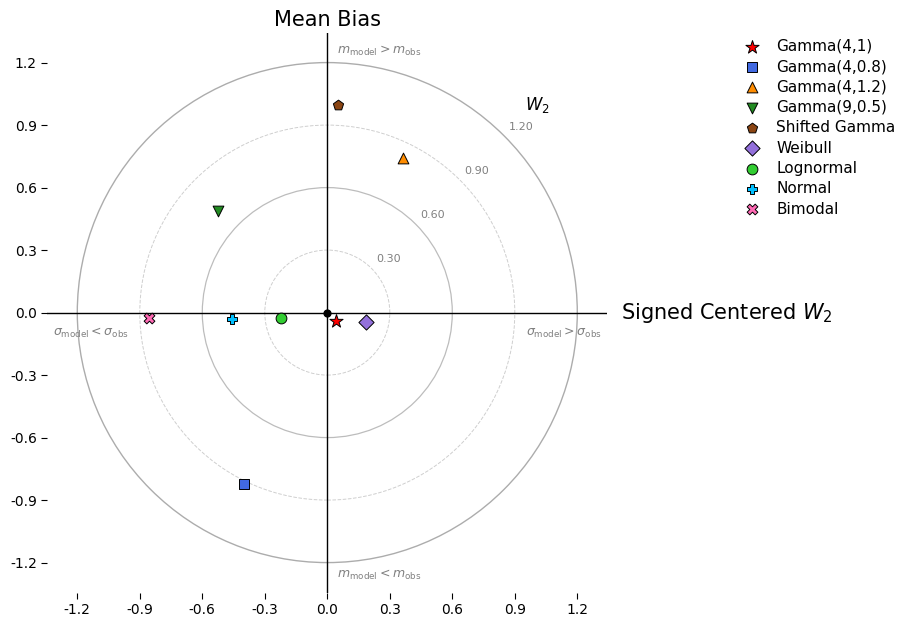

In [ ]:
# ============================================================
# Wasserstein Target Diagram: Simulation Study
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))


# ------------------------------------------------------------
# Determine outer W2 radius
# Always use exactly four circles
# ------------------------------------------------------------

max_w2 = np.max(W_2)

if max_w2 <= 0.1:
    outer_step = 0.05
elif max_w2 <= 0.2:
    outer_step = 0.10
elif max_w2 <= 0.5:
    outer_step = 0.20
elif max_w2 <= 1.0:
    outer_step = 0.40
elif max_w2 <= 2.0:
    outer_step = 0.80
elif max_w2 <= 5.0:
    outer_step = 2.0
elif max_w2 <= 10.0:
    outer_step = 4.0
else:
    outer_step = 4.0

rmax = np.ceil(max_w2 / outer_step) * outer_step

# Exactly four equally spaced circles
radii = np.array([rmax / 4, rmax / 2, 3 * rmax / 4, rmax])


# ------------------------------------------------------------
# Draw exactly four W2 circles
# 1st dashed, 2nd solid, 3rd dashed, 4th solid
# ------------------------------------------------------------

circle_styles = [
    ("--", 0.7, 0.38),
    ("-", 0.9, 0.52),
    ("--", 0.7, 0.38),
    ("-", 1.0, 0.65)
]

for r, (linestyle, linewidth, alpha) in zip(radii, circle_styles):
    circle = plt.Circle((0, 0), r, fill=False, edgecolor="gray",
                        linewidth=linewidth, linestyle=linestyle,
                        alpha=alpha, zorder=0)
    ax.add_patch(circle)


# ------------------------------------------------------------
# Label W2 contours
# Label second and outer circles only
# ------------------------------------------------------------

theta = np.pi / 4

for i in [0,1,2,3]:
    r = radii[i]
    ax.text((r + 0.025 * rmax) * np.cos(theta),
            (r + 0.025 * rmax) * np.sin(theta),
            f"{r:.2f}", fontsize=8, color="gray",
            ha="left", va="bottom")


# ------------------------------------------------------------
# W2 label
# ------------------------------------------------------------

ax.text((rmax * 1.12) * np.cos(theta),
        (rmax * 1.12) * np.sin(theta),
        r"$W_2$", fontsize=12, color="black",
        ha="left", va="bottom")


# ------------------------------------------------------------
# Model colors and markers
# ------------------------------------------------------------

# Highlight the correctly specified model in red
model_colors = {
    "Gamma(4,1)": "red",
    "Gamma(4,0.8)": "royalblue",
    "Gamma(4,1.2)": "darkorange",
    "Gamma(9,0.5)": "forestgreen",
    "Shifted Gamma": "saddlebrown",
    "Weibull": "mediumpurple",
    "Lognormal": "limegreen",
    "Normal": "deepskyblue",
    "Bimodal": "hotpink"
}

model_markers = {
    "Gamma(4,1)": "*",
    "Gamma(4,0.8)": "s",
    "Gamma(4,1.2)": "^",
    "Gamma(9,0.5)": "v",
    "Shifted Gamma": "p",
    "Weibull": "D",
    "Lognormal": "o",
    "Normal": "P",
    "Bimodal": "X"
}



# ------------------------------------------------------------
# Plot models
# ------------------------------------------------------------

for x, y, name in zip(
    Signed_Centered_W2,
    Bias,
    Model_short
):

    color = model_colors[name]
    marker = model_markers[name]

    # Highlight the same-distribution prediction
    if name == "Gamma(4,1)":
        size = 100
        linewidth = 0.7
    else:
        size = 60
        linewidth = 0.7

    ax.scatter(
        x,
        y,
        s=size,
        marker=marker,
        facecolor=color,
        edgecolor="black",
        linewidth=linewidth,
        label=name,
        zorder=3
    )


# ------------------------------------------------------------
# Reference coordinate axes
# ------------------------------------------------------------

ax.axhline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)

ax.axvline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)


# ------------------------------------------------------------
# Perfect-fit target
# ------------------------------------------------------------

# Origin represents perfect agreement
ax.scatter(
    0,
    0,
    s=24,
    color="black",
    zorder=4
)


# ------------------------------------------------------------
# Axis limits and aspect ratio
# ------------------------------------------------------------

limit = rmax * 1.12

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)

# Equal scaling preserves circular W2 contours
ax.set_aspect(
    "equal",
    adjustable="box"
)


# ------------------------------------------------------------
# Remove conventional outer box and axis labels
# ------------------------------------------------------------

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")


# ------------------------------------------------------------
# Coordinate titles
# ------------------------------------------------------------

# Horizontal coordinate title
ax.text(
    limit * 1.05,
    0,
    r"Signed Centered $W_2$",
    fontsize=15,
    ha="left",
    va="center",
    clip_on=False
)

# Vertical coordinate title
ax.text(
    0,
    limit * 1.01,
    "Mean Bias",
    fontsize=15,
    ha="center",
    va="bottom",
    clip_on=False
)


# ------------------------------------------------------------
# Interpretation of coordinate signs
# ------------------------------------------------------------

# Smaller model standard deviation
ax.text(
    -limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}<\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Larger model standard deviation
ax.text(
    limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}>\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="right",
    va="top"
)

# Larger model mean
ax.text(
    0.035 * limit,
    limit * 0.96,
    r"$m_{\mathrm{model}}>m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Smaller model mean
ax.text(
    0.035 * limit,
    -limit * 0.96,
    r"$m_{\mathrm{model}}<m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="bottom"
)


# ------------------------------------------------------------
# Model legend
# ------------------------------------------------------------

ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
    bbox_to_anchor=(1.22, 1.00),
    handletextpad=0.6,
    labelspacing=0.35,
    borderaxespad=0
)


# ------------------------------------------------------------
# Tick locations: four ticks on each side of each axis
# ------------------------------------------------------------

ticks = np.linspace(-rmax, rmax, 9)

ax.set_xticks(ticks)
ax.set_yticks(ticks)

# Adaptive number formatting
from matplotlib.ticker import FormatStrFormatter

if rmax < 1:
    tick_format = "%.2f"
elif rmax < 10:
    tick_format = "%.1f"
else:
    tick_format = "%.0f"

ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))

ax.tick_params(direction="out", labelsize=10, length=4)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.97
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "/content/sample_data/Simulation_Unequal_Length_Wasserstein_Target_Diagram.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()